# 15 · MLflow: seguimiento de experimentos y registro de modelos

MLflow no está en el `requirements.txt` del repo (los notebooks corren sin servidores ni internet),
así que aquí no lo importamos. En su lugar:

1. Armamos un **mini MLflow** de unas 40 líneas para ver qué guarda de verdad un run: parámetros,
   métricas, tags y runs anidados. Así la interfaz de MLflow deja de ser una caja negra.
2. Repetimos el análisis del **generador de datos del tutorial** de MLflow (`ejemplos/manzanas.py`,
   el archivo real del Taller 3) y sus dos errores.
3. Comparamos modelos **al azar contra en el tiempo** y registramos los 16 runs en el mini MLflow.
4. Simulamos lo que guarda el **autolog** con una búsqueda de hiperparámetros sobre el dataset de
   la Champions.
5. Hacemos un **Model Registry** en miniatura: versiones y un alias que se mueve.

El código con MLflow de verdad está en `ejemplos/` (ver el README del tema).

In [1]:
import sys
import time
import uuid
import warnings
from contextlib import contextmanager
from datetime import datetime
from unittest import mock

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import f1_score, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, SplineTransformer, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sys.path.insert(0, "ejemplos")  # para importar ejemplos/manzanas.py
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. Un mini MLflow

Un **run** es un registro de un entrenamiento: qué parámetros se usaron, qué métricas salieron y
unas etiquetas (tags) para buscarlo después. Un **experimento** agrupa runs del mismo problema, y
un run puede tener **runs hijos** (por ejemplo, una búsqueda de hiperparámetros con una
combinación por hijo).

La clase de abajo imita la API *fluent* de MLflow (`set_experiment`, `start_run`, `log_params`,
`log_metrics`, `set_tags`, `search_runs`). Igual que MLflow, guarda los **parámetros como texto** y
las **métricas como números**, y `start_run` dentro de otro `start_run` crea un hijo.

In [2]:
class MiniMLflow:
    """Imitación mínima del Tracking de MLflow, en memoria."""

    def __init__(self):
        self.runs, self._activos, self.experimento = [], [], "Default"

    def set_experiment(self, nombre):
        self.experimento = nombre

    @contextmanager
    def start_run(self, run_name):
        padre = self._activos[-1]["run_id"] if self._activos else None
        run = {"run_id": uuid.uuid4().hex[:8], "experimento": self.experimento, "nombre": run_name,
               "padre": padre, "params": {}, "metrics": {}, "tags": {}, "inicio": time.time()}
        self.runs.append(run)
        self._activos.append(run)
        try:
            yield run
        finally:
            self._activos.pop()

    def log_params(self, params):
        self._activos[-1]["params"].update({k: str(v) for k, v in params.items()})  # texto, como MLflow

    def log_metrics(self, metricas):
        self._activos[-1]["metrics"].update({k: float(v) for k, v in metricas.items()})

    def set_tags(self, tags):
        self._activos[-1]["tags"].update(tags)

    def search_runs(self, experimento):
        """Un DataFrame con columnas params.*, metrics.* y tags.*, igual que mlflow.search_runs."""
        filas = []
        for r in self.runs:
            if r["experimento"] == experimento:
                fila = {"run_id": r["run_id"], "nombre": r["nombre"], "padre": r["padre"]}
                fila |= {f"params.{k}": v for k, v in r["params"].items()}
                fila |= {f"metrics.{k}": v for k, v in r["metrics"].items()}
                fila |= {f"tags.{k}": v for k, v in r["tags"].items()}
                filas.append(fila)
        return pd.DataFrame(filas)


mlflow = MiniMLflow()

Lo probamos con dos runs del primer modelo del tutorial: un `RandomForestRegressor` con
`max_depth` distinto. Cada `with` es un run.

In [3]:
from manzanas import efecto_cosecha, generar_datos_mejorado, generar_datos_tutorial

datos = generar_datos_tutorial(base_demand=1_000, n_rows=1_000)
X = datos.drop(columns=["date", "demand"])
X_train, X_val, y_train, y_val = train_test_split(X, datos["demand"], test_size=0.2, random_state=RANDOM_STATE)

mlflow.set_experiment("Apple_Models")
for profundidad in [6, 12]:
    params = {"n_estimators": 100, "max_depth": profundidad, "min_samples_leaf": 4, "random_state": 888}
    with mlflow.start_run(run_name=f"rf_profundidad_{profundidad}"):
        modelo = RandomForestRegressor(**params).fit(X_train, y_train)
        pred = modelo.predict(X_val)
        mlflow.log_params(params)
        mlflow.log_metrics({"rmse": np.sqrt(mean_squared_error(y_val, pred)), "r2": r2_score(y_val, pred)})

mlflow.search_runs("Apple_Models").round(3)

,run_id,nombre,padre,params.n_estimators,params.max_depth,params.min_samples_leaf,params.random_state,metrics.rmse,metrics.r2
0,db656845,rf_profundidad_6,None,100,6,4,888,60.156,0.885
1,7ba76fe2,rf_profundidad_12,None,100,12,4,888,62.129,0.878


**Interpretación:** cada run quedó como una fila. Los parámetros aparecen como texto (`'100'`,
`'6'`) y las métricas como números, igual que en MLflow. Con `max_depth=12` el RMSE sube de 60.2 a
62.1: un bosque más profundo no ayuda con estos datos. Es la misma tabla que muestra la interfaz de
MLflow, solo que allá queda guardada en un servidor y no se pierde al cerrar el notebook.

## 2. El generador del tutorial y sus dos errores

El tutorial *Your First MLflow Model* genera la demanda diaria de manzanas con

$$\text{demanda} = (1000 - 50\cdot\text{precio} + 50\cdot\text{cosecha} + 200\cdot\text{promo}
+ 300\cdot\text{fin de semana} + \varepsilon)\times\text{inflación}$$

### 2.1 La cosecha siempre vale cero

El efecto de cosecha es `sin(2π(mes−3)/12) + sin(2π(mes−9)/12)`. Pero `mes − 9` es `mes − 3`
menos medio periodo, y `sin(x − π) = −sin(x)`: los dos senos se cancelan.

Valor máximo de |cosecha| en el tutorial: 7.771561172376096e-16 (cero salvo redondeo)


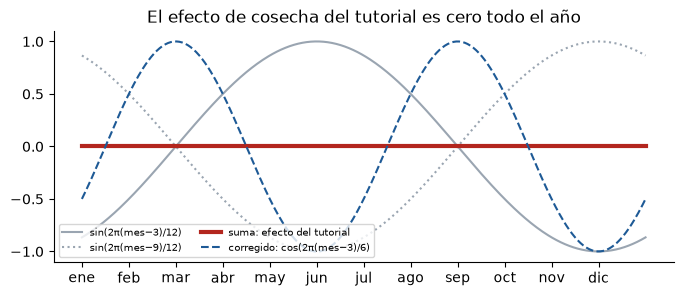

In [4]:
meses = np.linspace(1, 13, 400)
seno_a = np.sin(2 * np.pi * (meses - 3) / 12)
seno_b = np.sin(2 * np.pi * (meses - 9) / 12)
print("Valor máximo de |cosecha| en el tutorial:", np.abs(seno_a + seno_b).max(), "(cero salvo redondeo)")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(meses, seno_a, color="#9AA5B1", label="sin(2π(mes−3)/12)")
ax.plot(meses, seno_b, color="#9AA5B1", ls=":", label="sin(2π(mes−9)/12)")
ax.plot(meses, seno_a + seno_b, color="#B3261E", lw=3, label="suma: efecto del tutorial")
ax.plot(meses, efecto_cosecha(meses), color="#1E5A96", ls="--", label="corregido: cos(2π(mes−3)/6)")
ax.set_xticks(range(1, 13), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
ax.legend(fontsize=7, ncols=2, loc="lower left")
ax.set_title("El efecto de cosecha del tutorial es cero todo el año")
plt.show()

El comentario del código pone las promociones en abril y octubre "un mes después del pico de
cosecha", así que la intención eran picos en **marzo y septiembre**. Un solo coseno de periodo seis
meses, `cos(2π(mes−3)/6)`, hace justo eso.

### 2.2 Con la misma semilla, los datos cambian según el día

El generador fija `np.random.seed(9999)`, pero las fechas salen de `datetime.now()`. Si se corre
otro día, cada fila cae en otro día de la semana y cambia `weekend` y la demanda. Para comprobarlo
sin esperar a mañana, reemplazamos `datetime` dentro del módulo por uno con `now()` fijo.

In [5]:
import manzanas


class RelojFijo(datetime):
    momento = datetime(2026, 10, 13, 9, 0)

    @classmethod
    def now(cls, tz=None):
        return cls.momento


def generar_el(dia, n_rows=1_000):
    RelojFijo.momento = dia
    with mock.patch.object(manzanas, "datetime", RelojFijo):
        return manzanas.generar_datos_tutorial(base_demand=1_000, n_rows=n_rows)


hoy = generar_el(datetime(2026, 10, 13, 9, 0))
manana = generar_el(datetime(2026, 10, 14, 9, 0))
cambia = ~np.isclose(hoy["demand"], manana["demand"])
print(f"Misma semilla, otro día: cambia la demanda de {cambia.sum()} de {len(hoy)} filas ({cambia.mean():.0%})")
print("Generador corregido, dos llamadas iguales:", generar_datos_mejorado(n_rows=1_000).equals(generar_datos_mejorado(n_rows=1_000)))

Misma semilla, otro día: cambia la demanda de 296 de 1000 filas (30%)


Generador corregido, dos llamadas iguales: True


**Interpretación:** con la misma semilla, 296 de las 1,000 filas (30 %) cambian de demanda solo
porque el generador se corrió un día después. La semilla fija los números aleatorios, pero no la
fecha. La versión corregida (`generar_datos_mejorado`) termina en una fecha fija y da exactamente los
mismos datos en cada llamada.

## 3. ¿Validar al azar o en el tiempo?

El tutorial divide los días **al azar**. En una serie de tiempo eso deja que el modelo entrene con
días posteriores a los que valida. Lo honesto es entrenar con el pasado y validar con el **último
20 %** de los días. Comparamos cuatro modelos en los dos generadores y con las dos divisiones, y
registramos los 16 casos como runs hijos de un run `comparacion`, igual que en el Taller 3.

Los modelos "con fecha" reciben, además de las columnas del tutorial, los **años transcurridos** y
la **época del año** (senos y cosenos anuales y semestrales).

In [6]:
COLUMNAS = ["average_temperature", "rainfall", "weekend", "holiday", "price_per_kg", "promo", "previous_days_demand"]
PARAMS_TUTORIAL = {"n_estimators": 100, "max_depth": 6, "min_samples_split": 10, "min_samples_leaf": 4, "random_state": 888}


def con_fecha(df):
    dias = (df["date"] - pd.Timestamp("2000-01-01")).dt.days
    angulo = 2 * np.pi * df["date"].dt.dayofyear / 365.25
    return df[COLUMNAS].assign(anios=dias / 365.25, anual_sin=np.sin(angulo), anual_cos=np.cos(angulo),
                               semestral_sin=np.sin(2 * angulo), semestral_cos=np.cos(2 * angulo))


def modelos():
    fecha = FunctionTransformer(con_fecha)
    return {
        "rf_tutorial": RandomForestRegressor(**PARAMS_TUTORIAL),
        "rf_con_fecha": make_pipeline(fecha, RandomForestRegressor(**PARAMS_TUTORIAL)),
        "hgb_con_fecha": make_pipeline(fecha, HistGradientBoostingRegressor(random_state=888)),
        "ridge_con_fecha": make_pipeline(
            fecha,
            ColumnTransformer([("temperatura", SplineTransformer(n_knots=6), ["average_temperature"])], remainder="passthrough"),
            StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    }


def dividir(df, como):
    if como == "aleatoria":
        return train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
    corte = int(len(df) * 0.8)
    return df.iloc[:corte], df.iloc[corte:]


DATASETS = {"tutorial": generar_el(datetime(2026, 10, 13, 9, 0), n_rows=5_000), "mejorado": generar_datos_mejorado(n_rows=5_000)}

mlflow.set_experiment("Manzanas_Mejoras")
with mlflow.start_run(run_name="comparacion"):
    for nombre_datos, df in DATASETS.items():
        for division in ["aleatoria", "temporal"]:
            entrena, valida = dividir(df, division)
            for nombre_modelo, modelo in modelos().items():
                columnas = COLUMNAS if nombre_modelo == "rf_tutorial" else COLUMNAS + ["date"]
                pred = modelo.fit(entrena[columnas], entrena["demand"]).predict(valida[columnas])
                with mlflow.start_run(run_name=f"{nombre_modelo} | {nombre_datos} | {division}"):
                    mlflow.set_tags({"datos": nombre_datos, "division": division, "modelo": nombre_modelo})
                    mlflow.log_metrics({"rmse": np.sqrt(mean_squared_error(valida["demand"], pred)),
                                        "r2": r2_score(valida["demand"], pred)})

runs = mlflow.search_runs("Manzanas_Mejoras").dropna(subset=["metrics.rmse"])
print(f"{len(runs)} runs hijos")
runs.pivot_table(index="tags.modelo", columns=["tags.datos", "tags.division"], values="metrics.rmse").round(1)

16 runs hijos


tags.datos       mejorado           tutorial         
tags.division   aleatoria temporal aleatoria temporal
tags.modelo                                          
hgb_con_fecha        65.5     96.7      62.6     96.4
rf_con_fecha         89.1    132.3      63.1    102.1
rf_tutorial         127.7    205.9     124.4    199.6
ridge_con_fecha      64.4     79.1      63.0     77.3

In [7]:
runs.pivot_table(index="tags.modelo", columns=["tags.datos", "tags.division"], values="metrics.r2").round(3)

tags.datos       mejorado           tutorial         
tags.division   aleatoria temporal aleatoria temporal
tags.modelo                                          
hgb_con_fecha       0.931    0.858     0.938    0.835
rf_con_fecha        0.872    0.734     0.937    0.815
rf_tutorial         0.737    0.356     0.754    0.294
ridge_con_fecha     0.933    0.905     0.937    0.894

**Interpretación:** con la división al azar, el bosque del tutorial explica el 75 % de la varianza
(R² 0.754); en el tiempo, solo el 29 % (0.294), y su RMSE sube de 124.4 a 199.6. Darle la fecha al
mismo bosque baja el RMSE temporal a 102.1, y la regresión lineal con la fecha a 77.3. Los árboles
solo predicen valores parecidos a los que vieron y no pueden seguir la inflación hacia arriba; el
modelo lineal sí. Son los mismos números del Taller 3.

## 4. Lo que guarda el autolog con una búsqueda de hiperparámetros

Con `mlflow.sklearn.autolog()`, cada `fit` se registra solo. Cuando lo que se entrena es un
`RandomizedSearchCV` sobre un pipeline, MLflow reparte la información así:

- **Run padre:** los parámetros de la **búsqueda** (`cv`, `n_iter`, `estimator`...) y los mejores
  valores (`best_*`); métricas calculadas sobre el conjunto de **entrenamiento** (`training_*`) y
  `best_cv_score`.
- **Runs hijos** (las mejores `max_tuning_runs`, 5 por defecto): **todos** los parámetros del
  pipeline (`get_params(deep=True)`) y las métricas de la validación cruzada.

Lo simulamos con el dataset de la Champions (sin `score` ni `winner`, que revelan el resultado) y un
pipeline parecido al del curso.

In [8]:
partidos = pd.read_csv("../datos/champions_league_matches.csv").dropna(how="all")
X = partidos.drop(columns=["result", "score", "winner", "date", "venue", "referee"])
y = partidos["result"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)


def porcentaje(df):
    return df.apply(lambda c: c.astype(str).str.rstrip("%").replace("nan", np.nan).astype(float))


def razon(df):
    partes = [df[c].astype(str).str.extract(r"(\d+)\s*of\s*(\d+)").astype(float) for c in df.columns]
    return pd.concat(partes, axis=1).to_numpy()


preprocesamiento = ColumnTransformer([
    ("numericas", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
     ["home_shots_on_target_pct", "away_shots_on_target_pct", "home_saves_pct", "away_saves_pct"]),
    ("porcentajes", make_pipeline(FunctionTransformer(porcentaje), SimpleImputer(strategy="median"), StandardScaler()),
     ["home_possession", "away_possession"]),
    ("razones", make_pipeline(FunctionTransformer(razon), SimpleImputer(strategy="median"), StandardScaler()),
     ["home_shots_on_target", "away_shots_on_target", "home_saves", "away_saves"]),
    ("equipos", OneHotEncoder(handle_unknown="ignore"), ["home_team", "away_team"]),
])
pipe = Pipeline([("preprocesamiento", preprocesamiento), ("modelo", RandomForestClassifier(random_state=RANDOM_STATE))])
print("Parámetros del pipeline con get_params(deep=True):", len(pipe.get_params(deep=True)))

busqueda = RandomizedSearchCV(
    pipe,
    {"modelo__n_estimators": [100, 200, 400], "modelo__max_depth": [None, 4, 6, 10],
     "modelo__min_samples_leaf": [1, 2, 4], "modelo__class_weight": [None, "balanced"]},
    n_iter=20, scoring="f1_macro", cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train, y_train)

Parámetros del pipeline con get_params(deep=True): 107


Ahora lo registramos como lo haría el autolog: el padre con la búsqueda y las métricas de
entrenamiento; las 5 mejores combinaciones como hijos con el pipeline completo. La métrica de
prueba la agregamos aparte, como la registra el autolog cuando se llama a `sklearn.metrics`.

In [9]:
mlflow.set_experiment("Champions_Resultado")
resultados = pd.DataFrame(busqueda.cv_results_)
with mlflow.start_run(run_name="autolog-random-forest") as padre:
    params_busqueda = {k: v for k, v in busqueda.get_params(deep=False).items()}
    mlflow.log_params(params_busqueda | {f"best_{k}": v for k, v in busqueda.best_params_.items()})
    mlflow.log_metrics({
        "training_f1_score": f1_score(y_train, busqueda.predict(X_train), average="macro"),
        "best_cv_score": busqueda.best_score_,
        "f1_score_X_test": f1_score(y_test, busqueda.predict(X_test), average="macro"),
    })
    for _, fila in resultados.nsmallest(5, "rank_test_score").iterrows():
        with mlflow.start_run(run_name=f"combinacion_{int(fila['rank_test_score'])}"):
            mlflow.log_params(pipe.set_params(**fila["params"]).get_params(deep=True))
            mlflow.log_metrics({"mean_test_score": fila["mean_test_score"], "std_test_score": fila["std_test_score"]})

champions = mlflow.search_runs("Champions_Resultado")
corto = champions[["nombre", "padre", "metrics.training_f1_score", "metrics.best_cv_score", "metrics.f1_score_X_test", "metrics.mean_test_score"]]
print("Parámetros del padre:", len(mlflow.runs[-6]["params"]), "· de cada hijo:", len(mlflow.runs[-1]["params"]))
corto.round(3)

Parámetros del padre: 16 · de cada hijo: 107


,nombre,padre,metrics.training_f1_score,metrics.best_cv_score,metrics.f1_score_X_test,metrics.mean_test_score
0,autolog-random-forest,NaN,0.978,0.594,0.591,NaN
1,combinacion_1,eab2dd3d,NaN,NaN,NaN,0.594
2,combinacion_2,eab2dd3d,NaN,NaN,NaN,0.571
3,combinacion_3,eab2dd3d,NaN,NaN,NaN,0.568
4,combinacion_4,eab2dd3d,NaN,NaN,NaN,0.547
5,combinacion_5,eab2dd3d,NaN,NaN,NaN,0.526


**Interpretación:** el padre tiene 16 parámetros (la búsqueda y los mejores valores) y cada hijo
107, el pipeline completo. En el Taller 3, con el pipeline del curso y un hiperparámetro más en la
búsqueda, fueron 17 y 106. El F1 de entrenamiento (0.978) parece casi perfecto, pero el de
validación cruzada (0.594) y el de prueba (0.591) cuentan la historia real. En un run del autolog hay
que fijarse en `best_cv_score` y en la métrica de prueba, no en las `training_*`.

## 5. Un Model Registry en miniatura

El **Model Registry** guarda versiones de un modelo con nombre. Cada registro crea una versión
nueva (1, 2, 3...) y un **alias** (`@campeon`) apunta a la que se debe usar. El código de producción
carga siempre `models:/champions-resultado@campeon`; para cambiar de modelo, o regresar al anterior,
solo se mueve el alias.

In [10]:
registro = {}


def registrar(nombre, modelo):
    versiones = registro.setdefault(nombre, {"versiones": {}, "alias": {}})["versiones"]
    version = len(versiones) + 1
    versiones[version] = modelo
    return version


def asignar_alias(nombre, alias, version):
    registro[nombre]["alias"][alias] = version


def cargar(uri):
    """Acepta models:/nombre/version o models:/nombre@alias, como MLflow."""
    ruta = uri.removeprefix("models:/")
    if "@" in ruta:
        nombre, alias = ruta.split("@")
        return registro[nombre]["versiones"][registro[nombre]["alias"][alias]]
    nombre, version = ruta.split("/")
    return registro[nombre]["versiones"][int(version)]


logistica = Pipeline([("preprocesamiento", preprocesamiento),
                      ("modelo", LogisticRegression(max_iter=5000, class_weight="balanced"))]).fit(X_train, y_train)
v1 = registrar("champions-resultado", busqueda.best_estimator_)
v2 = registrar("champions-resultado", logistica)

URI = "models:/champions-resultado@campeon"  # lo único que conoce "producción"
for version in [v1, v2]:
    asignar_alias("champions-resultado", "campeon", version)
    modelo = cargar(URI)
    print(f"@campeon -> v{version} ({type(modelo[-1]).__name__}): F1 macro en prueba "
          f"{f1_score(y_test, modelo.predict(X_test), average='macro'):.3f}")

@campeon -> v1 (RandomForestClassifier): F1 macro en prueba 0.591
@campeon -> v2 (LogisticRegression): F1 macro en prueba 0.497


**Interpretación:** el código que carga el modelo (`URI`) nunca cambió. Al mover `@campeon` de la
versión 1 (bosque, F1 0.591) a la 2 (regresión logística, 0.497), producción recibió otro modelo. Aquí
la versión 2 es peor, así que lo correcto sería regresar el alias a la 1: un *rollback* en una línea,
sin volver a desplegar nada.

## Resumen

- Un **run** es un registro de un entrenamiento: parámetros (como texto), métricas (como números),
  tags y, con MLflow, archivos y el modelo. Un experimento agrupa runs y un run puede tener hijos.
- El generador del tutorial tenía dos errores: la **cosecha siempre vale cero** y los datos
  **dependen del día** en que se corre, aunque la semilla esté fija.
- En una serie de tiempo hay que **validar en el tiempo**: la división al azar hace ver mucho mejor
  a un modelo que no sabe extrapolar la tendencia.
- Con una búsqueda, el **autolog** pone el detalle del pipeline en los runs hijos y sus métricas del
  padre son de **entrenamiento**; la de prueba hay que calcularla dentro del run.
- El **Model Registry** separa el modelo que se entrenó del que se usa: producción carga el alias y
  no cambia su código cuando cambia el modelo.